EDA


In [5]:
import pandas as pd 
import seaborn as sns 
import openpyxl

In [6]:
df = pd.read_excel('task_feedback_dataset_Python_GenAI1.xlsm')
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 272 entries, 0 to 271
Data columns (total 22 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   DATETIME                       272 non-null    str    
 1   TASK                           272 non-null    str    
 2   FEEDBACK_SOURCE / METRIC       271 non-null    str    
 3   LLM_USAGE                      268 non-null    str    
 4   PROMPT                         147 non-null    str    
 5   RESEARCH_TIME (in minutes)     248 non-null    object 
 6   TOTAL_TIME_TAKEN (in minutes)  271 non-null    float64
 7   SUCCESS_RATE (out of 5)        269 non-null    float64
 8   COMMENTS                       202 non-null    str    
 9   DOUBTS                         50 non-null     str    
 10  Unnamed: 10                    24 non-null     str    
 11  Unnamed: 11                    1 non-null      float64
 12  Unnamed: 12                    0 non-null      float64
 13  U

In [7]:
df.head()


,DATETIME,TASK,FEEDBACK_SOURCE / METRIC,LLM_USAGE,PROMPT,RESEARCH_TIME (in minutes),TOTAL_TIME_TAKEN (in minutes),SUCCESS_RATE (out of 5),COMMENTS,DOUBTS,...,Unnamed: 12,Unnamed: 13,Unnamed: 14,Unnamed: 15,Unnamed: 16,Unnamed: 17,Unnamed: 18,Unnamed: 19,Unnamed: 20,FEEDBACK_SOURCE_CATEGORIES
0,2026-11-3 1244,developing a script to convert Q-language to P...,Q() score,Yes,"""script to convert Q-language to PySpark """,30,60.0,4.0,Example row,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,metric
1,2026-11-2 1900,Guitar practice,1 minute switches,No,NaN,30,90.0,1.0,example row,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,human
2,2026-11-03 1400,Creating a data pipeline,data ingestion,Yes,How to create a data ingestion pipeline,30,90.0,5.0,data ingested successfully,Mention main steps,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,intuition
3,2026-11-03 1500,Creating a document for AI basics,Understanding AI basics,Yes,AI Basics for beginners,60,120.0,4.0,NaN,What topic did you explore in this session?,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,2026-11-03 1600,Reorganizing important emails,Email organizing,No,NaN,10,30.0,4.0,NaN,Result of organization? Success rating?,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [8]:
df['DATETIME'] = pd.to_datetime(df['DATETIME'], format='mixed')
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 272 entries, 0 to 271
Data columns (total 22 columns):
 #   Column                         Non-Null Count  Dtype         
---  ------                         --------------  -----         
 0   DATETIME                       272 non-null    datetime64[us]
 1   TASK                           272 non-null    str           
 2   FEEDBACK_SOURCE / METRIC       271 non-null    str           
 3   LLM_USAGE                      268 non-null    str           
 4   PROMPT                         147 non-null    str           
 5   RESEARCH_TIME (in minutes)     248 non-null    object        
 6   TOTAL_TIME_TAKEN (in minutes)  271 non-null    float64       
 7   SUCCESS_RATE (out of 5)        269 non-null    float64       
 8   COMMENTS                       202 non-null    str           
 9   DOUBTS                         50 non-null     str           
 10  Unnamed: 10                    24 non-null     str           
 11  Unnamed: 11                   

In [9]:
date = df['DATETIME'].dt.date
date

0      2026-11-03
1      2026-11-02
2      2026-11-03
3      2026-11-03
4      2026-11-03
          ...    
267    2026-11-09
268    2026-11-10
269    2026-11-10
270    2026-11-10
271    2026-11-10
Name: DATETIME, Length: 272, dtype: object

In [10]:
time = df['DATETIME'].dt.time
time

0      12:44:00
1      19:00:00
2      14:00:00
3      15:00:00
4      16:00:00
         ...   
267    20:00:00
268    08:00:00
269    13:00:00
270    15:00:00
271    20:00:00
Name: DATETIME, Length: 272, dtype: object

In [11]:
df['DATE'] = df['DATETIME'].dt.date
df['TIME'] = df['DATETIME'].dt.time
df.head()

,DATETIME,TASK,FEEDBACK_SOURCE / METRIC,LLM_USAGE,PROMPT,RESEARCH_TIME (in minutes),TOTAL_TIME_TAKEN (in minutes),SUCCESS_RATE (out of 5),COMMENTS,DOUBTS,...,Unnamed: 14,Unnamed: 15,Unnamed: 16,Unnamed: 17,Unnamed: 18,Unnamed: 19,Unnamed: 20,FEEDBACK_SOURCE_CATEGORIES,DATE,TIME
0,2026-11-03 12:44:00,developing a script to convert Q-language to P...,Q() score,Yes,"""script to convert Q-language to PySpark """,30,60.0,4.0,Example row,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,metric,2026-11-03,12:44:00
1,2026-11-02 19:00:00,Guitar practice,1 minute switches,No,NaN,30,90.0,1.0,example row,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,human,2026-11-02,19:00:00
2,2026-11-03 14:00:00,Creating a data pipeline,data ingestion,Yes,How to create a data ingestion pipeline,30,90.0,5.0,data ingested successfully,Mention main steps,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,intuition,2026-11-03,14:00:00
3,2026-11-03 15:00:00,Creating a document for AI basics,Understanding AI basics,Yes,AI Basics for beginners,60,120.0,4.0,NaN,What topic did you explore in this session?,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2026-11-03,15:00:00
4,2026-11-03 16:00:00,Reorganizing important emails,Email organizing,No,NaN,10,30.0,4.0,NaN,Result of organization? Success rating?,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2026-11-03,16:00:00


In [12]:
# tasks_per_day = df.groupby('DATE').agg({'#': count()})
tasks_per_day = df.groupby('DATE', as_index=False).agg(count=('DATE', 'count'))
tasks_per_day

,DATE,count
0,2016-11-03,1
1,2026-11-02,2
2,2026-11-03,45
3,2026-11-04,43
4,2026-11-05,35
5,2026-11-06,28
6,2026-11-07,24
7,2026-11-08,24
8,2026-11-09,21
9,2026-11-10,27


In [13]:
tasks_per_day['count'].mean()

np.float64(22.666666666666668)

In [14]:
tasks_per_day['count'].sum()

np.int64(272)

<Axes: xlabel='DATE', ylabel='count'>

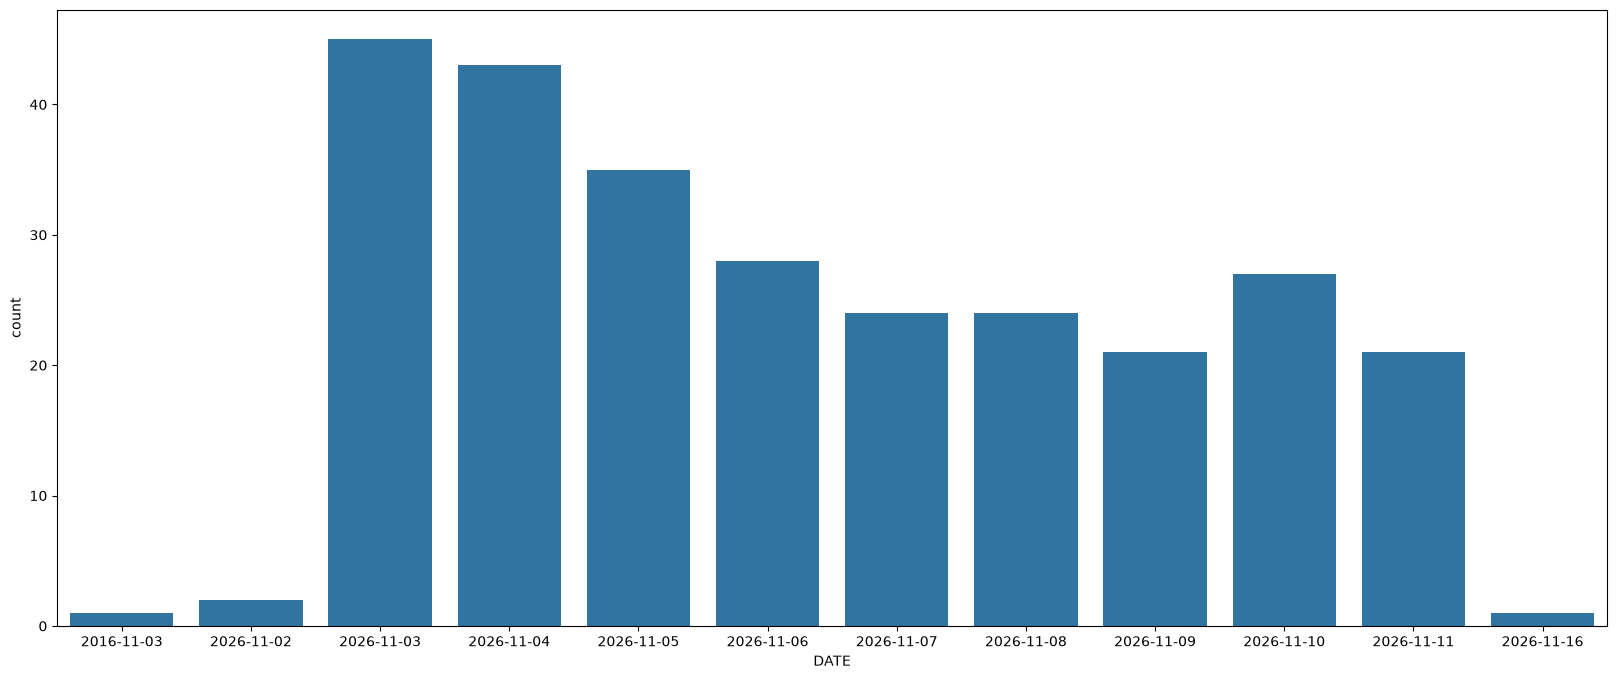

In [15]:
import matplotlib.pyplot as plt

plt.figure(figsize=(20,8))
sns.barplot(data=tasks_per_day, x=tasks_per_day['DATE'], y=tasks_per_day['count'])

In [16]:
df['LLM_USAGE'].value_counts()

LLM_USAGE
No      108
Yes      85
no       33
yes      21
yes      19
NO        2
Name: count, dtype: int64

In [17]:
def clean_boolean(entry):
    if entry.islike(r'Yes|yes'):
        return 1
    else:
        return 0

# df['LLM_USAGE'] = df['LLM_USAGE'].map(lambda x : clean_boolean(x))
df['LLM_USAGE'] = df['LLM_USAGE'].str.contains('yes', case=False, na=False).astype(int)

Observations
we are a population of 17

expected average tasks per day would be 17 * 4 = 68

actual average tasks per day = 23

our motivation lasts for 2 days on end before we need a boost (?)

either the tasks were non-technical or too simple that we didn't need the help of LLMs for 147/272 tasks

we tried our best to not use LLMs for our tasks

LLM

In [40]:
import os
from openai import OpenAI
import requests
import json

In [66]:
SYSTEM_PROMPT = """
You are a generalist tutor. You have a wide range of skills and are to be examining the skills and tasks of the user
Rules:
- Take in the task title, feedback source and task rating as input
- based on the task and the rating, ask questions that will confirm the rating by the user. i.e., examine the user's knowledge or skill as per their rating of the tasks
- Respond with your version or suggestion of a better feedback source if applicable
- The ratings are out of 5.
- If you do not know how to respond, say so.

Example input:
Title = Learning python lists and dictionaries
Feedback_source = Practice exercises
Rating = 4
"""

BASE_URL = 'https://openai.generative.engine.capgemini.com/v1'

MODEL = "qwen.qwen3-coder-next"

API_KEY = os.environ.get('AI_KEY')

In [68]:
class LLMClient:

    def __init__(self):
        self.client = OpenAI(
            base_url=BASE_URL,
            api_key=API_KEY,
            timeout=60.0
        )

    def ask(self, prompt, temperature=0):

        response = self.client.chat.completions.create(
            model=MODEL,
            messages=[
                {"role": "system", "content": SYSTEM_PROMPT},
                {
                    "role": "user",
                    "content": prompt
                }
            ],
            temperature=temperature,
            max_completion_tokens=6000
        )

        return response.choices[0].message.content

    def close(self):
        self.client.close()

In [71]:
print (API_KEY)

sk-dJMWS3I28E1i5pZIQQq-PQ


In [69]:
input_json = """
{"Task": "Riding a Moped",
"Feedback_source": "Self learning",
"Rating": "4"}
"""

client = LLMClient()
response = client.ask(json.dumps(input_json))
print(response)

Thanks for the input! A rating of **4/5** for *Riding a Moped* using *Self learning* as the feedback source suggests the user feels fairly confident but sees room for improvement—perhaps in safety, handling, or real-world conditions.

To confirm and explore this rating, here are a few targeted questions:

1. **Skill Application**: When riding on your own, how often do you encounter situations (e.g., tight turns, heavy traffic, wet roads) where you felt uncertain or less in control?  
2. **Safety & Awareness**: Have you practiced emergency braking or evasive maneuvers? If so, how confident are you in executing them safely?  
3. **Regulatory Knowledge**: Are you fully comfortable with local moped laws (e.g., lane positioning, helmet requirements, licensing)?  
4. **Self-Assessment Gap**: What specific aspect of riding do you feel is *just shy* of mastery—e.g., starting/stopping smoothly, balancing at low speeds, or parking?

Also, as a suggestion:  
🔹 **Better Feedback Source?** While se

In [61]:
import pandas as pd
import numpy as np
import ollama
import seaborn
import os

BASE_URL = os.environ.get('BASE_ENDPOINT')
API_KEY = os.environ.get('AI_KEY')

In [62]:
from ollama import Client

client = Client(host=BASE_URL, timeout=120)
response = client.chat(model="qwen.qwen3-coder-next", messages=[
    {"role" : "user", "content": "what is your name?"}
])

print(response.message.content)

ResponseError: {"message":"Unauthorized"}
 (status code: 401)

In [63]:
import os

from dotenv import load_dotenv
from openai import OpenAI

load_dotenv()

BASE_URL = "https://openai.generative.engine.capgemini.com/v1"

API_KEY = os.environ.get("AI_KEY")

MODEL = os.environ.get(
    "AIPG_MODEL",
    "qwen.qwen3-coder-next"
)

if not API_KEY:
    raise ValueError(
        "AIPG_API_KEY environment variable not set."
    )


class LLMClient:

    def __init__(self):
        self.client = OpenAI(
            base_url=BASE_URL,
            api_key=API_KEY,
            timeout=60.0
        )

    def ask(self, prompt, temperature=0):

        response = self.client.chat.completions.create(
            model=MODEL,
            messages=[
                {
                    "role": "user",
                    "content": prompt
                }
            ],
            temperature=temperature,
            max_completion_tokens=6000
        )

        return response.choices[0].message.content

    def close(self):
        self.client.close()

In [64]:
client = LLMClient()

client.ask('what is your name?')

"My name is Qwen. I'm a large-scale language model developed by Alibaba Cloud's Tongyi Lab. It's a pleasure to serve you! 😊"

In [65]:
import requests

url = f"{BASE_URL}/models"
headers = {
    "Authorization": f"Bearer {API_KEY}"
}
response = requests.get(url=url, headers=headers)
models = response.json()
models

{'data': [{'id': 'anthropic.claude-sonnet-4-5-20250929-v1:0',
   'object': 'model',
   'created': 1677610602,
   'owned_by': 'openai',
   'mode': 'chat',
   'max_input_tokens': 200000,
   'max_output_tokens': 64000},
  {'id': 'claude-sonnet-4-5-20250929',
   'object': 'model',
   'created': 1677610602,
   'owned_by': 'openai',
   'mode': 'chat',
   'max_input_tokens': 200000,
   'max_output_tokens': 64000},
  {'id': 'anthropic.claude-haiku-4-5-20251001-v1:0',
   'object': 'model',
   'created': 1677610602,
   'owned_by': 'openai',
   'mode': 'chat',
   'max_input_tokens': 200000,
   'max_output_tokens': 64000},
  {'id': 'claude-haiku-4-5-20251001',
   'object': 'model',
   'created': 1677610602,
   'owned_by': 'openai',
   'mode': 'chat',
   'max_input_tokens': 200000,
   'max_output_tokens': 64000},
  {'id': 'anthropic.claude-opus-4-5-20251101-v1:0',
   'object': 'model',
   'created': 1677610602,
   'owned_by': 'openai',
   'mode': 'chat',
   'max_input_tokens': 200000,
   'max_outpu

In [58]:
class LLMClient:

    def __init__(self):
        self.client = OpenAI(
            base_url=BASE_URL,
            api_key=API_KEY,
            timeout=60.0
        )

    def ask(self, prompt, temperature=0):

        response = self.client.chat.completions.create(
            model=MODEL,
            messages=[
                {"role": "system", "content": SYSTEM_PROMPT},
                {
                    "role": "user",
                    "content": prompt
                }
            ],
            temperature=temperature,
            max_completion_tokens=6000
        )

        return response.choices[0].message.content

    def close(self):
        self.client.close()

In [59]:
input_json = """
{"Task": "Riding a Moped",
"Feedback_source": "Self learning",
"Rating": "4"}
"""

client = LLMClient()
response = client.ask(json.dumps(input_json))
print(response)

Thanks for the input! A rating of **4/5** for *Riding a Moped* using *Self learning* as the feedback source suggests the user feels fairly confident but sees room for improvement—perhaps in safety awareness, handling tricky situations, or mastering finer controls.

To confirm and explore this rating, here are a few targeted questions:

1. **Confidence & Safety**: When riding solo (e.g., in traffic or on uneven terrain), how often do you second-guess your decisions or feel uncertain about your control?
2. **Skill Gaps**: Are there specific maneuvers (e.g., tight U-turns, emergency braking, hill starts, or riding in rain/wind) where you feel less confident?
3. **Feedback Limitation**: Since you’re self-learning, have you ever had someone more experienced observe you ride and give feedback—or do you rely solely on trial-and-error?
4. **Progress Tracking**: How do you measure improvement? (e.g., reduced anxiety over time, smoother starts/stops, completing longer/complex routes)

Also, as a

SCRATCHPAD  

In [60]:
import pandas as pd
import numpy as np
import ollama
import seaborn
import os

BASE_URL = os.environ.get('BASE_ENDPOINT')
API_KEY = os.environ.get('AI_KEY')

ModuleNotFoundError: No module named 'Langchain'